# Affine registration on random Gaussian images

Estimate a full 2D affine warp of a random grayscale image after additive Gaussian noise. As in `rotation_registration.ipynb`, every pixel of the template is drawn independently from a standard normal. The unknown transform has six degrees of freedom: rotation, anisotropic scale, shear, and translation.

**Method choice.** OpenCV's `findTransformECC` (`MOTION_AFFINE`) and scikit-image's registration helpers are aimed at natural images with multi-scale structure. On white-noise fields they do not recover the warp reliably, even with Gaussian pre-blur. This notebook therefore uses SciPy only: bilinear `ndimage.affine_transform`, a coarse SSD grid over angle and translation, `least_squares` refinement of all six parameters, and `differential_evolution` only when the local refine leaves a large residual. No optimizer is implemented from scratch.

Results are written under `results/affine_registration/`.


## 1. Configuration

Reduce `N_TRIALS` for a smoke test. Parameter ranges keep linear maps comfortably away from singularity (`sx, sy` near 1, small shear).


In [1]:
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage
from scipy.optimize import differential_evolution, least_squares

SEED = 42
IMAGE_SIZE = 64
NOISE_LEVELS = [0.0, 0.1, 0.25, 0.5, 1.0]
N_TRIALS = 100
WARP_ORDER = 1  # bilinear

# Ground-truth / search bounds for the six parameters.
ANGLE_RANGE = (-15.0, 15.0)  # degrees
SCALE_RANGE = (0.9, 1.1)
SHEAR_RANGE = (-0.1, 0.1)
TRANSLATION_RANGE = (-3.0, 3.0)  # pixels

COARSE_ANGLE_STEP = 2.0
COARSE_TRANSLATION_STEP = 2.0
RMSE_FALLBACK = 0.05  # trigger differential evolution if above this (template intensity units)
VALID_RADIUS_FRAC = 0.32  # circular ROI radius as a fraction of image side

OUTPUT_DIR = Path("results/affine_registration")
FIGURES_DIR = OUTPUT_DIR / "figures"

PARAM_NAMES = ["angle_deg", "scale_x", "scale_y", "shear", "tx", "ty"]
BOUNDS = [ANGLE_RANGE, SCALE_RANGE, SCALE_RANGE, SHEAR_RANGE, TRANSLATION_RANGE, TRANSLATION_RANGE]
LB = np.array([b[0] for b in BOUNDS], dtype=float)
UB = np.array([b[1] for b in BOUNDS], dtype=float)

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"image {IMAGE_SIZE}x{IMAGE_SIZE}, trials/noise={N_TRIALS}, noise={NOISE_LEVELS}")
print(f"output -> {OUTPUT_DIR.resolve()}")


image 64x64, trials/noise=100, noise=[0.0, 0.1, 0.25, 0.5, 1.0]
output -> C:\Users\samco\OneDrive\Desktop\gaussian_rotation\results\affine_registration


## 2. Transform convention and valid region

**Parameterization.** A parameter vector
\(\mathbf{p} = (\theta, s_x, s_y, k, t_x, t_y)\)
builds the linear map
\[
A = R(\theta)\,
\begin{bmatrix} s_x & s_x k \\ 0 & s_y \end{bmatrix},
\]
with translation \(\mathbf{t} = (t_x, t_y)\) in pixels. Angles are in degrees. With the configured ranges, \(|\det A|\) stays near 1.

**Centered forward warp.** Let \(c\) be the image center in pixel coordinates \((N/2 - 1/2,\, N/2 - 1/2)\). Template coordinates relative to the center are mapped by
\[
q' = A q + t, \qquad p' = q' + c, \qquad p = q + c.
\]
SciPy's `affine_transform` samples with the inverse map (destination \(\to\) source). The observation is
\[
Y = W_{A,t}(I) + \sigma\varepsilon.
\]

**Valid region.** Changing overlap would bias SSD. Every score uses the same circular mask of radius `VALID_RADIUS_FRAC * N` about the center. That disk stays inside the image under the configured prior; it is not recomputed per candidate. Absolute difference plots also use this mask.

**Optimization.** Coarse SSD over \(\theta, t_x, t_y\) with \((s_x,s_y,k)=(1,1,0)\), then bounded `least_squares` on all six parameters (`xtol/ftol/gtol=1e-10`). If the RMSE against the observation still exceeds \(\texttt{RMSE\_FALLBACK}\) when \(\sigma=0\), or \(1.1\sigma + \texttt{RMSE\_FALLBACK}\) when \(\sigma>0\), run `differential_evolution` over the same bounds and polish with `least_squares`. The threshold scales with \(\sigma\) because even a perfect warp leaves an observation residual of order \(\sigma\). Limits: bilinear interpolation of white noise, local minima on the SSD landscape, and DE cost when the coarse start is poor. OpenCV ECC was checked and rejected for this noise model.


In [2]:
def params_to_matrix(params: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    angle, sx, sy, shear, tx, ty = np.asarray(params, dtype=float)
    theta = np.deg2rad(angle)
    cos_t, sin_t = np.cos(theta), np.sin(theta)
    rotation = np.array([[cos_t, -sin_t], [sin_t, cos_t]], dtype=float)
    linear = np.array([[sx, sx * shear], [0.0, sy]], dtype=float)
    return rotation @ linear, np.array([tx, ty], dtype=float)


def image_center(shape: tuple[int, int]) -> np.ndarray:
    return np.array(shape, dtype=float) / 2.0 - 0.5


def warp_affine(image: np.ndarray, matrix: np.ndarray, translation: np.ndarray) -> np.ndarray:
    center = image_center(image.shape)
    inverse = np.linalg.inv(matrix)
    affine = np.zeros((2, 3), dtype=float)
    affine[:, :2] = inverse
    affine[:, 2] = -inverse @ (center + translation) + center
    return ndimage.affine_transform(
        image,
        affine,
        order=WARP_ORDER,
        mode="constant",
        cval=0.0,
        prefilter=True,
    )


def circular_valid_mask(shape: tuple[int, int], radius_frac: float = VALID_RADIUS_FRAC) -> np.ndarray:
    height, width = shape
    center_y, center_x = image_center(shape)
    rows, cols = np.mgrid[0:height, 0:width]
    radius = radius_frac * float(min(height, width))
    return (rows - center_y) ** 2 + (cols - center_x) ** 2 <= radius ** 2


def sample_params(rng: np.random.Generator) -> np.ndarray:
    for _ in range(1000):
        params = np.array(
            [
                rng.uniform(*ANGLE_RANGE),
                rng.uniform(*SCALE_RANGE),
                rng.uniform(*SCALE_RANGE),
                rng.uniform(*SHEAR_RANGE),
                rng.uniform(*TRANSLATION_RANGE),
                rng.uniform(*TRANSLATION_RANGE),
            ],
            dtype=float,
        )
        matrix, _ = params_to_matrix(params)
        if abs(np.linalg.det(matrix)) >= 0.7:
            return params
    raise RuntimeError("failed to sample a well-conditioned affine transform")


VALID_MASK = circular_valid_mask((IMAGE_SIZE, IMAGE_SIZE))
print(f"valid pixels: {int(VALID_MASK.sum())} / {IMAGE_SIZE * IMAGE_SIZE} ({100 * VALID_MASK.mean():.1f}%)")


valid pixels: 1304 / 4096 (31.8%)


In [3]:
def ssd_cost(template: np.ndarray, observation: np.ndarray, params: np.ndarray, mask: np.ndarray) -> float:
    warped = warp_affine(template, *params_to_matrix(params))
    residual = warped[mask] - observation[mask]
    return float(residual @ residual)


def residual_vector(template: np.ndarray, observation: np.ndarray, params: np.ndarray, mask: np.ndarray) -> np.ndarray:
    warped = warp_affine(template, *params_to_matrix(params))
    return warped[mask] - observation[mask]


def coarse_initialize(template: np.ndarray, observation: np.ndarray, mask: np.ndarray) -> np.ndarray:
    best_params = None
    best_cost = np.inf
    angles = np.arange(ANGLE_RANGE[0], ANGLE_RANGE[1] + 0.5 * COARSE_ANGLE_STEP, COARSE_ANGLE_STEP)
    shifts = np.arange(
        TRANSLATION_RANGE[0],
        TRANSLATION_RANGE[1] + 0.5 * COARSE_TRANSLATION_STEP,
        COARSE_TRANSLATION_STEP,
    )
    for angle in angles:
        for tx in shifts:
            for ty in shifts:
                params = np.array([angle, 1.0, 1.0, 0.0, tx, ty], dtype=float)
                cost = ssd_cost(template, observation, params, mask)
                if cost < best_cost:
                    best_cost = cost
                    best_params = params
    return best_params


def register_affine(
    template: np.ndarray,
    observation: np.ndarray,
    mask: np.ndarray,
    noise_std: float = 0.0,
) -> dict:
    started = time.perf_counter()
    init = coarse_initialize(template, observation, mask)

    def fun(params: np.ndarray) -> np.ndarray:
        return residual_vector(template, observation, params, mask)

    refined = least_squares(
        fun,
        init,
        bounds=(LB, UB),
        xtol=1e-10,
        ftol=1e-10,
        gtol=1e-10,
        max_nfev=400,
    )
    estimate = refined.x.copy()
    rmse = float(np.sqrt(np.mean(fun(estimate) ** 2)))
    method = "coarse+least_squares"
    # Residual to a noisy observation is ~sigma even at the true warp. A wrong
    # local minimum is typically closer to sqrt(2+sigma^2). Use a threshold
    # just above sigma so DE runs only when the local refine looks inconsistent.
    fallback_threshold = (
        RMSE_FALLBACK if float(noise_std) <= 0.0 else (1.1 * float(noise_std) + RMSE_FALLBACK)
    )
    if rmse > fallback_threshold:
        de = differential_evolution(
            lambda params: ssd_cost(template, observation, params, mask),
            BOUNDS,
            polish=True,
            tol=1e-6,
            popsize=6,
            seed=SEED,
        )
        refined = least_squares(
            fun,
            de.x,
            bounds=(LB, UB),
            xtol=1e-10,
            ftol=1e-10,
            gtol=1e-10,
            max_nfev=200,
        )
        estimate = refined.x.copy()
        rmse = float(np.sqrt(np.mean(fun(estimate) ** 2)))
        method = "differential_evolution+least_squares"

    elapsed = time.perf_counter() - started
    return {
        "estimated_params": estimate,
        "init_params": init,
        "rmse": rmse,
        "method": method,
        "runtime_s": elapsed,
        "nfev": int(refined.nfev),
        "fallback_threshold": fallback_threshold,
    }


def alignment_rmse(template: np.ndarray, params_a: np.ndarray, params_b: np.ndarray, mask: np.ndarray) -> float:
    image_a = warp_affine(template, *params_to_matrix(params_a))
    image_b = warp_affine(template, *params_to_matrix(params_b))
    residual = image_a[mask] - image_b[mask]
    return float(np.sqrt(np.mean(residual ** 2)))


def matrix_frobenius_error(params_a: np.ndarray, params_b: np.ndarray) -> float:
    matrix_a, translation_a = params_to_matrix(params_a)
    matrix_b, translation_b = params_to_matrix(params_b)
    linear = np.linalg.norm(matrix_a - matrix_b, ord="fro")
    shift = np.linalg.norm(translation_a - translation_b)
    return float(np.sqrt(linear**2 + shift**2))


# Warm-up timing.
_rng = np.random.default_rng(0)
_template = _rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
_true = sample_params(_rng)
_obs = warp_affine(_template, *params_to_matrix(_true))
_t0 = time.perf_counter()
_fit = register_affine(_template, _obs, VALID_MASK, noise_std=0.0)
print(
    f"warm-up: method={_fit['method']}, rmse={_fit['rmse']:.3e}, "
    f"runtime={_fit['runtime_s']:.3f}s, param MAE={np.mean(np.abs(_fit['estimated_params'] - _true)):.3e}"
)


warm-up: method=coarse+least_squares, rmse=8.634e-15, runtime=0.052s, param MAE=2.692e-15


## 3. Example trial

One matched draw at \(\sigma = 0.25\): template, clean warp, noisy observation, then the estimated warp and absolute residual on the valid mask.


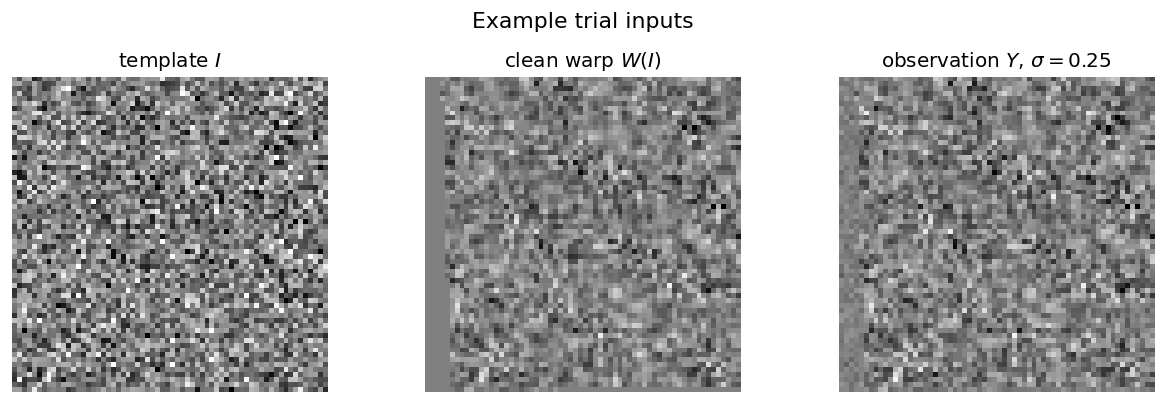

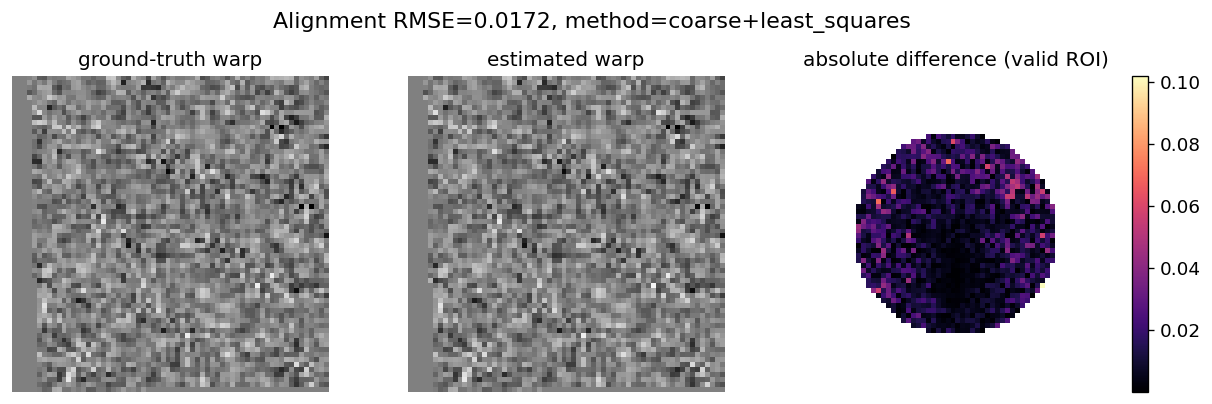

parameter     true  estimated  abs_error unit
angle_deg  1.57076    1.54154    0.02922  deg
  scale_x  1.06718    1.06682    0.00036    1
  scale_y  0.95596    0.95653    0.00057    1
    shear  0.00383    0.00236    0.00147    1
       tx -2.29512   -2.29463    0.00049   px
       ty  2.30766    2.31466    0.00700   px
matrix+translation error=0.00715, runtime=0.059s


In [4]:
example_rng = np.random.default_rng(SEED)
example_template = example_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
example_true = sample_params(example_rng)
example_clean = warp_affine(example_template, *params_to_matrix(example_true))
example_noise = 0.25
example_obs = example_clean + example_noise * example_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
example_fit = register_affine(example_template, example_obs, VALID_MASK, noise_std=example_noise)
example_est = example_fit["estimated_params"]
example_est_image = warp_affine(example_template, *params_to_matrix(example_est))
example_abs = np.abs(example_est_image - example_clean)
example_abs_masked = np.where(VALID_MASK, example_abs, np.nan)

vmax = float(np.percentile(np.abs(example_template), 99))
fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
for ax, img, title in zip(
    axes,
    [example_template, example_clean, example_obs],
    ["template $I$", r"clean warp $W(I)$", fr"observation $Y$, $\sigma={example_noise}$"],
):
    ax.imshow(img, cmap="gray", vmin=-vmax, vmax=vmax, interpolation="nearest")
    ax.set_title(title)
    ax.axis("off")
fig.suptitle("Example trial inputs")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "example_inputs.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(10.5, 3.4))
axes[0].imshow(example_clean, cmap="gray", vmin=-vmax, vmax=vmax, interpolation="nearest")
axes[0].set_title("ground-truth warp")
axes[1].imshow(example_est_image, cmap="gray", vmin=-vmax, vmax=vmax, interpolation="nearest")
axes[1].set_title("estimated warp")
im = axes[2].imshow(example_abs_masked, cmap="magma", interpolation="nearest")
axes[2].set_title("absolute difference (valid ROI)")
for ax in axes:
    ax.axis("off")
fig.colorbar(im, ax=axes[2], fraction=0.046)
fig.suptitle(
    fr"Alignment RMSE={alignment_rmse(example_template, example_true, example_est, VALID_MASK):.4f}, "
    fr"method={example_fit['method']}"
)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "example_alignment.png", bbox_inches="tight")
plt.show()

compare = pd.DataFrame({
    "parameter": PARAM_NAMES,
    "true": example_true,
    "estimated": example_est,
    "abs_error": np.abs(example_est - example_true),
    "unit": ["deg", "1", "1", "1", "px", "px"],
})
print(compare.round(5).to_string(index=False))
print(
    f"matrix+translation error={matrix_frobenius_error(example_true, example_est):.5f}, "
    f"runtime={example_fit['runtime_s']:.3f}s"
)


## 4. Full experiment

Templates and ground-truth transforms are identical across noise levels. Only the noise draw changes with \(\sigma\).


In [5]:
def run_experiment(n_trials: int, noise_levels: list[float], seed: int) -> pd.DataFrame:
    rows = []
    started = time.perf_counter()
    total = n_trials * len(noise_levels)
    done = 0
    for trial in range(n_trials):
        trial_rng = np.random.default_rng(seed + 10_000 * trial + IMAGE_SIZE)
        template = trial_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
        true_params = sample_params(trial_rng)
        clean = warp_affine(template, *params_to_matrix(true_params))
        for noise_std in noise_levels:
            noise_rng = np.random.default_rng(seed + 10_000 * trial + int(1_000_000 * noise_std) + 11)
            observation = clean + noise_std * noise_rng.standard_normal((IMAGE_SIZE, IMAGE_SIZE))
            fit = register_affine(template, observation, VALID_MASK, noise_std=float(noise_std))
            est = fit["estimated_params"]
            row = {
                "trial": trial,
                "noise_std": float(noise_std),
                "method": fit["method"],
                "runtime_s": fit["runtime_s"],
                "rmse_to_observation": fit["rmse"],
                "alignment_rmse": alignment_rmse(template, true_params, est, VALID_MASK),
                "matrix_error": matrix_frobenius_error(true_params, est),
                "used_de": fit["method"].startswith("differential_evolution"),
            }
            for name, truth, hat in zip(PARAM_NAMES, true_params, est):
                row[f"true_{name}"] = float(truth)
                row[f"est_{name}"] = float(hat)
                row[f"abs_err_{name}"] = float(abs(hat - truth))
            rows.append(row)
            done += 1
            if done == 1 or done == total or done % max(1, total // 10) == 0:
                elapsed = time.perf_counter() - started
                rate = done / max(elapsed, 1e-9)
                eta = (total - done) / rate
                print(
                    f"[{done}/{total}] trial={trial} sigma={noise_std:g} "
                    f"align_rmse={row['alignment_rmse']:.4f} method={row['method']} "
                    f"elapsed={elapsed:.1f}s eta={eta:.1f}s",
                    flush=True,
                )
    return pd.DataFrame(rows)


results = run_experiment(N_TRIALS, NOISE_LEVELS, SEED)
results_path = OUTPUT_DIR / "trial_results.csv"
results.to_csv(results_path, index=False)
print(f"wrote {results_path} ({len(results)} rows)")
print(f"DE fallback rate: {results.used_de.mean():.2%}")


[1/500] trial=0 sigma=0 align_rmse=0.0000 method=differential_evolution+least_squares elapsed=1.7s eta=842.3s


[50/500] trial=9 sigma=1 align_rmse=0.0761 method=coarse+least_squares elapsed=13.1s eta=117.7s


[100/500] trial=19 sigma=1 align_rmse=0.1264 method=coarse+least_squares elapsed=17.5s eta=70.2s


[150/500] trial=29 sigma=1 align_rmse=0.0920 method=coarse+least_squares elapsed=22.8s eta=53.2s


[200/500] trial=39 sigma=1 align_rmse=0.0475 method=coarse+least_squares elapsed=26.2s eta=39.3s


...

[350/500] trial=69 sigma=1 align_rmse=0.0584 method=coarse+least_squares elapsed=41.9s eta=18.0s


[400/500] trial=79 sigma=1 align_rmse=0.0266 method=differential_evolution+least_squares elapsed=52.4s eta=13.1s


[450/500] trial=89 sigma=1 align_rmse=0.0397 method=coarse+least_squares elapsed=56.6s eta=6.3s


[500/500] trial=99 sigma=1 align_rmse=0.0487 method=differential_evolution+least_squares elapsed=68.7s eta=0.0s


wrote results\affine_registration\trial_results.csv (500 rows)
DE fallback rate: 10.80%


## 5. Summary tables

Parameter errors are not interchangeable: angle is in degrees, scales and shear are dimensionless, translations are in pixels. Matrix error combines the Frobenius norm of \(A\) with \(\|t\|_2\) in pixel units. Alignment RMSE is the image-space residual between the ground-truth warp and the estimated warp on the valid mask (noise-free comparison).


In [6]:
summary_rows = []
for noise_std, block in results.groupby("noise_std"):
    row = {
        "noise_std": float(noise_std),
        "n": int(len(block)),
        "mean_alignment_rmse": float(block.alignment_rmse.mean()),
        "std_alignment_rmse": float(block.alignment_rmse.std(ddof=1)),
        "mean_matrix_error": float(block.matrix_error.mean()),
        "std_matrix_error": float(block.matrix_error.std(ddof=1)),
        "mean_runtime_s": float(block.runtime_s.mean()),
        "std_runtime_s": float(block.runtime_s.std(ddof=1)),
        "de_fraction": float(block.used_de.mean()),
    }
    for name in PARAM_NAMES:
        col = f"abs_err_{name}"
        row[f"mae_{name}"] = float(block[col].mean())
        row[f"std_{name}"] = float(block[col].std(ddof=1))
    summary_rows.append(row)
summary = pd.DataFrame(summary_rows).sort_values("noise_std").reset_index(drop=True)
summary_path = OUTPUT_DIR / "summary_by_noise.csv"
summary.to_csv(summary_path, index=False)

show = summary[
    [
        "noise_std",
        "mae_angle_deg",
        "mae_scale_x",
        "mae_scale_y",
        "mae_shear",
        "mae_tx",
        "mae_ty",
        "mean_alignment_rmse",
        "mean_matrix_error",
        "mean_runtime_s",
        "de_fraction",
    ]
].copy()
print(show.round(5).to_string(index=False))
zero = summary.loc[np.isclose(summary.noise_std, 0.0)].iloc[0]
print(
    f"\nZero-noise sanity: mean alignment RMSE={zero.mean_alignment_rmse:.3e}, "
    f"mean |angle| error={zero.mae_angle_deg:.3e} deg, DE fraction={zero.de_fraction:.2%}."
)


 noise_std  mae_angle_deg  mae_scale_x  mae_scale_y  mae_shear  mae_tx  mae_ty  mean_alignment_rmse  mean_matrix_error  mean_runtime_s  de_fraction
      0.00        0.00000      0.00000      0.00000    0.00000 0.00000 0.00000              0.00000            0.00000         0.20514         0.09
      0.10        0.00981      0.00019      0.00018    0.00027 0.00223 0.00167              0.00650            0.00313         0.09576         0.08
      0.25        0.02823      0.00037      0.00048    0.00063 0.00490 0.00558              0.01603            0.00847         0.09872         0.08
      0.50        0.06480      0.00103      0.00084    0.00143 0.01070 0.00934              0.03308            0.01596         0.10475         0.08
      1.00        0.10550      0.00214      0.00178    0.00253 0.02200 0.01935              0.06646            0.03331         0.18032         0.21

Zero-noise sanity: mean alignment RMSE=7.534e-14, mean |angle| error=1.521e-13 deg, DE fraction=9.00%.


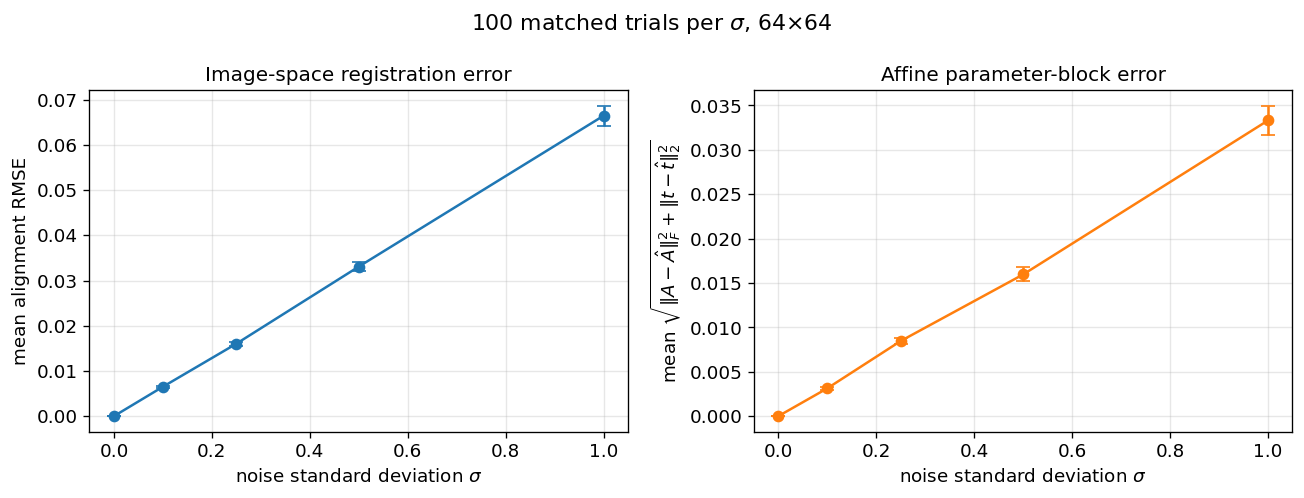

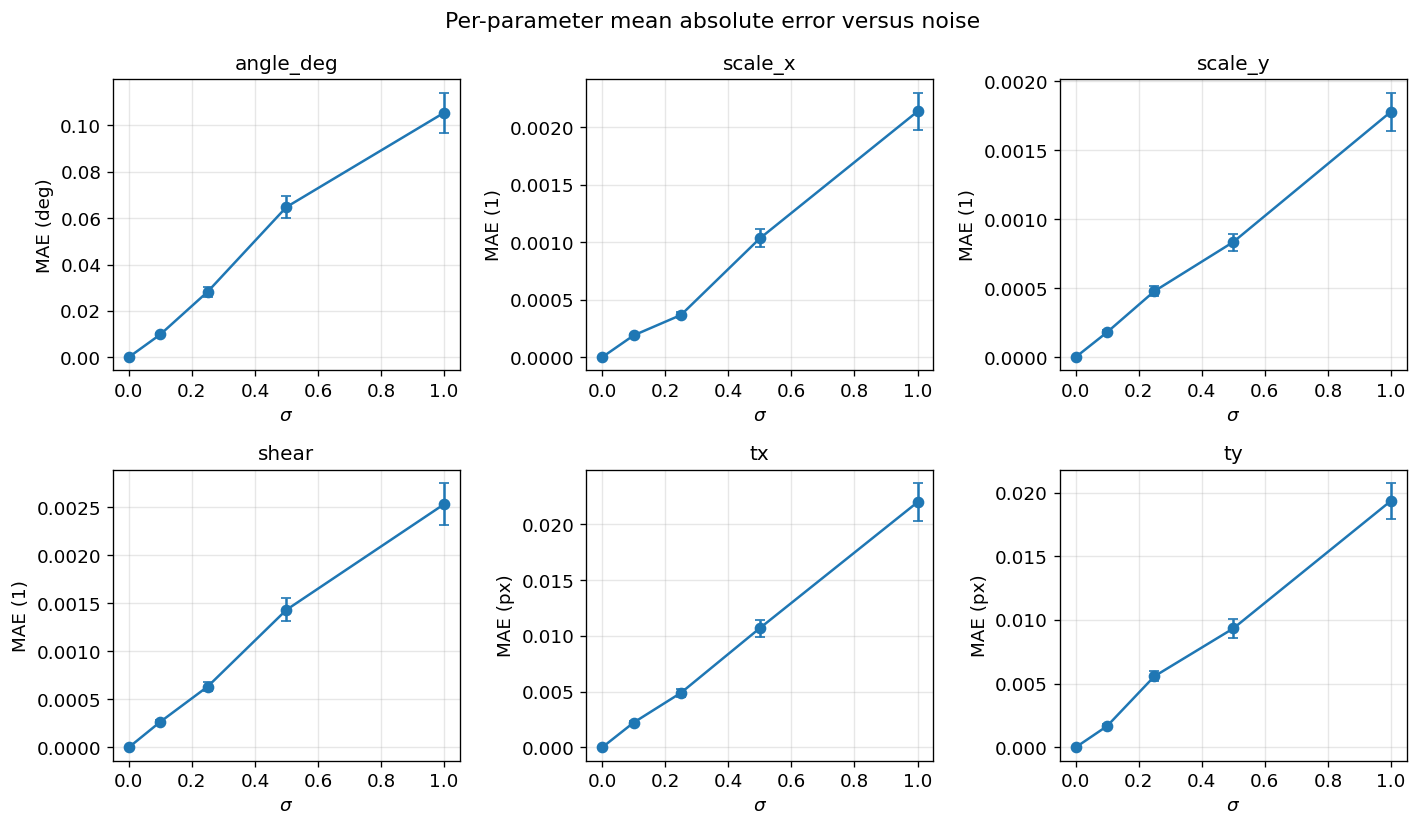

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].errorbar(
    summary.noise_std,
    summary.mean_alignment_rmse,
    yerr=summary.std_alignment_rmse / np.sqrt(summary.n),
    fmt="-o",
    capsize=4,
)
axes[0].set_xlabel(r"noise standard deviation $\sigma$")
axes[0].set_ylabel("mean alignment RMSE")
axes[0].set_title("Image-space registration error")

axes[1].errorbar(
    summary.noise_std,
    summary.mean_matrix_error,
    yerr=summary.std_matrix_error / np.sqrt(summary.n),
    fmt="-o",
    color="C1",
    capsize=4,
)
axes[1].set_xlabel(r"noise standard deviation $\sigma$")
axes[1].set_ylabel(r"mean $\sqrt{\|A-\hat A\|_F^2 + \|t-\hat t\|_2^2}$")
axes[1].set_title("Affine parameter-block error")
fig.suptitle(fr"{N_TRIALS} matched trials per $\sigma$, {IMAGE_SIZE}$\times${IMAGE_SIZE}")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "error_vs_noise.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, name, unit in zip(
    axes.ravel(),
    PARAM_NAMES,
    ["deg", "1", "1", "1", "px", "px"],
):
    means = summary[f"mae_{name}"]
    stds = summary[f"std_{name}"]
    ax.errorbar(summary.noise_std, means, yerr=stds / np.sqrt(summary.n), fmt="-o", capsize=3)
    ax.set_title(name)
    ax.set_xlabel(r"$\sigma$")
    ax.set_ylabel(f"MAE ({unit})")
fig.suptitle("Per-parameter mean absolute error versus noise")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "parameter_mae_vs_noise.png", bbox_inches="tight")
plt.show()


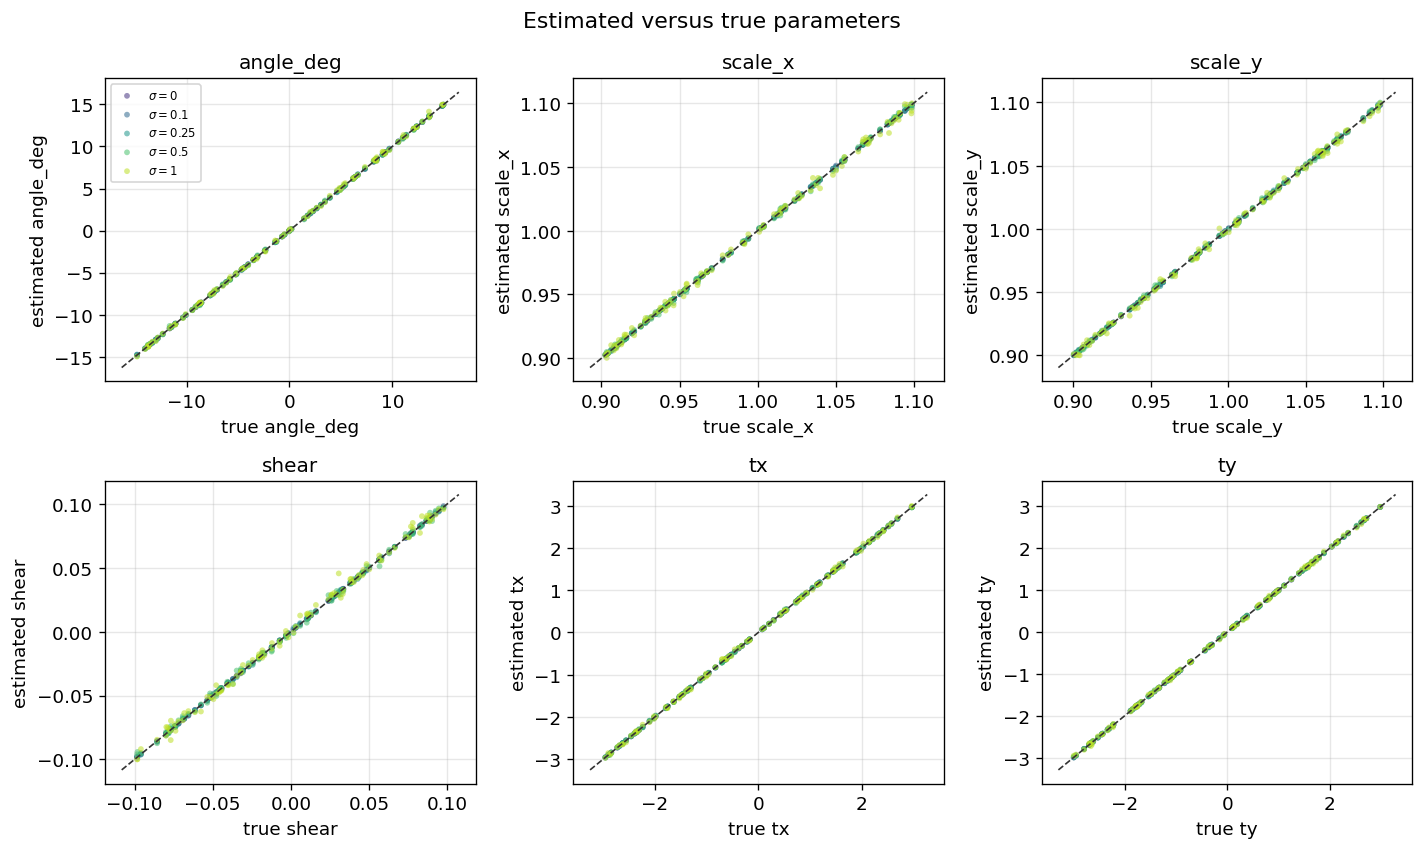

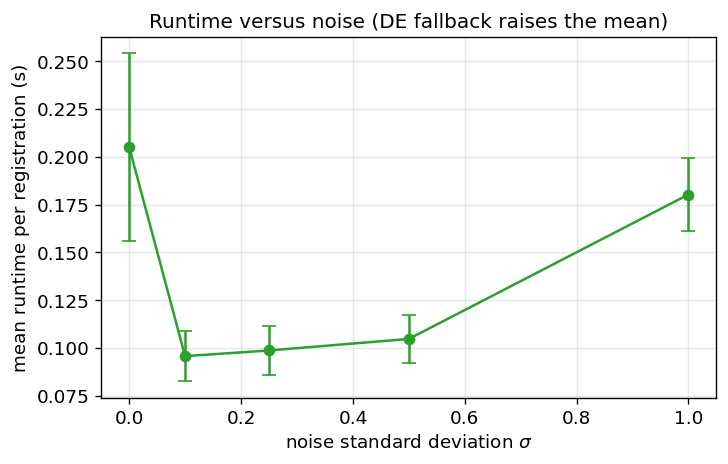

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7.2))
colors = plt.cm.viridis(np.linspace(0.15, 0.9, len(NOISE_LEVELS)))
for ax, name in zip(axes.ravel(), PARAM_NAMES):
    for noise_std, color in zip(NOISE_LEVELS, colors):
        block = results.loc[np.isclose(results.noise_std, noise_std)]
        ax.scatter(
            block[f"true_{name}"],
            block[f"est_{name}"],
            s=12,
            alpha=0.55,
            color=color,
            edgecolors="none",
            label=fr"$\sigma={noise_std:g}$",
        )
    lo = float(results[f"true_{name}"].min())
    hi = float(results[f"true_{name}"].max())
    pad = 0.05 * (hi - lo + 1e-9)
    ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], color="0.2", ls="--", lw=1)
    ax.set_xlabel(f"true {name}")
    ax.set_ylabel(f"estimated {name}")
    ax.set_title(name)
axes[0, 0].legend(fontsize=7, loc="best")
fig.suptitle("Estimated versus true parameters")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "estimated_vs_true_params.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.errorbar(
    summary.noise_std,
    summary.mean_runtime_s,
    yerr=summary.std_runtime_s / np.sqrt(summary.n),
    fmt="-o",
    color="C2",
    capsize=4,
)
ax.set_xlabel(r"noise standard deviation $\sigma$")
ax.set_ylabel("mean runtime per registration (s)")
ax.set_title("Runtime versus noise (DE fallback raises the mean)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "runtime_vs_noise.png", bbox_inches="tight")
plt.show()


## 6. Interpretation, outputs, and HiPerGator notes

**Dependencies.** `numpy`, `scipy`, `matplotlib`, `pandas`. CPU only. OpenCV / scikit-image are not required.

**Local run.** Open this notebook from the repository root and run all cells. For a quicker check, set `N_TRIALS = 10`.

**HiPerGator.** The existing `gaussian-rotation` env already has the SciPy stack. Copy the notebook, run from the repo root on a CPU notebook session or batch job, then copy back `results/affine_registration/`.

**Outputs.**

```text
results/affine_registration/trial_results.csv
results/affine_registration/summary_by_noise.csv
results/affine_registration/metadata.json
results/affine_registration/figures/*.png
```


In [9]:
metadata = {
    "seed": SEED,
    "image_size": IMAGE_SIZE,
    "n_trials": N_TRIALS,
    "noise_levels": NOISE_LEVELS,
    "parameterization": "angle_deg, scale_x, scale_y, shear, tx, ty with A = R @ [[sx, sx*shear], [0, sy]]",
    "bounds": {
        "angle_deg": list(ANGLE_RANGE),
        "scale": list(SCALE_RANGE),
        "shear": list(SHEAR_RANGE),
        "translation_px": list(TRANSLATION_RANGE),
    },
    "interpolation": "scipy.ndimage.affine_transform bilinear",
    "optimizer": "coarse SSD grid over angle/translation + scipy.optimize.least_squares; differential_evolution fallback",
    "valid_mask": f"circular radius {VALID_RADIUS_FRAC} * N",
    "valid_pixels": int(VALID_MASK.sum()),
    "rmse_fallback": RMSE_FALLBACK,
    "rmse_fallback_rule": "RMSE_FALLBACK if sigma==0 else 1.1*sigma + RMSE_FALLBACK",
    "opencv_ecc": "investigated; unreliable on white-noise templates; not used",
}
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

print("Interpretation")
print(
    f"- Zero-noise mean alignment RMSE is {zero.mean_alignment_rmse:.3e}. "
    "Residual error is interpolation and occasional DE polish, not a wrong transform family."
)
print(
    f"- At sigma={summary.noise_std.iloc[-1]:g}, mean alignment RMSE="
    f"{summary.mean_alignment_rmse.iloc[-1]:.4f} and mean |angle| error="
    f"{summary.mae_angle_deg.iloc[-1]:.4f} deg."
)
print(
    f"- Translations (px) and angles (deg) dominate the raw MAE table because their units are larger "
    f"than scale/shear. Compare matrix_error and alignment_rmse for a unit-aware summary."
)
print(
    f"- Mean runtime {summary.mean_runtime_s.mean():.3f}s; DE used on {100 * results.used_de.mean():.1f}% of registrations."
)
print(f"- Wrote {OUTPUT_DIR / 'metadata.json'}")


Interpretation
- Zero-noise mean alignment RMSE is 7.534e-14. Residual error is interpolation and occasional DE polish, not a wrong transform family.
- At sigma=1, mean alignment RMSE=0.0665 and mean |angle| error=0.1055 deg.
- Translations (px) and angles (deg) dominate the raw MAE table because their units are larger than scale/shear. Compare matrix_error and alignment_rmse for a unit-aware summary.
- Mean runtime 0.137s; DE used on 10.8% of registrations.
- Wrote results\affine_registration\metadata.json
